# 03 — 월드모델 학습

학습 목표(loss)는 두 가지입니다. 매 타임스텝 `t`에서:

1. **재구성 손실(reconstruction loss)**: `posterior_step`이 실제 관측(`frames[t]`)을 보고 만든
   `h_t`로 디코딩한 이미지가 진짜 `frames[t]`와 얼마나 비슷한가 (MSE).
2. **임베딩 예측 손실(embedding prediction loss)**: `embed_head(h_{t-1})`로 미리 예측한
   "이번에 볼 것 같은 임베딩"이 실제 인코더가 만든 임베딩과 얼마나 비슷한가 (MSE, target은
   detach). 이 loss가 있어야 `embed_head`가 "미래 관측 예측"을 배우고, 나중에 observation 없이
   굴러가는 `prior_step`(imagination)이 쓸모 있어집니다.

전체 시퀀스(T=40)를 teacher forcing으로 한 번에 굴리고, 두 손실을 합산해 역전파합니다.


In [1]:
import time
import torch
import matplotlib.pyplot as plt
import wm_toy as W

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

torch.manual_seed(0)
train_ds = W.WMSequenceDataset(num_episodes=96, T=40, base_seed=1000)
val_ds = W.WMSequenceDataset(num_episodes=16, T=40, base_seed=9000)

train_loader = torch.utils.data.DataLoader(train_ds, batch_size=8, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_ds, batch_size=8, shuffle=False)

model = W.WorldModel().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
mse = torch.nn.MSELoss()

def run_epoch(loader, train: bool):
    model.train(train)
    total_recon, total_embed, n_batches = 0.0, 0.0, 0
    for frames, actions, states in loader:
        frames, actions = frames.to(device), actions.to(device)
        B, T = frames.shape[0], frames.shape[1]
        h = model.init_hidden(B, device)
        recon_loss = torch.zeros((), device=device)
        embed_loss = torch.zeros((), device=device)
        for t in range(T):
            if t > 0:
                pred_embed = model.embed_head(h)
                with torch.no_grad():
                    target_embed = model.encoder(frames[:, t])
                embed_loss = embed_loss + mse(pred_embed, target_embed)
            h, recon, _ = model.posterior_step(h, frames[:, t], actions[:, t])
            recon_loss = recon_loss + mse(recon, frames[:, t])
        loss = recon_loss / T + 0.5 * embed_loss / T

        if train:
            opt.zero_grad()
            loss.backward()
            opt.step()

        total_recon += float(recon_loss / T)
        total_embed += float(embed_loss / T)
        n_batches += 1
    return total_recon / n_batches, total_embed / n_batches

EPOCHS = 12
history = {"train_recon": [], "train_embed": [], "val_recon": [], "val_embed": []}
t0 = time.time()
for epoch in range(EPOCHS):
    tr_r, tr_e = run_epoch(train_loader, train=True)
    with torch.no_grad():
        va_r, va_e = run_epoch(val_loader, train=False)
    history["train_recon"].append(tr_r); history["train_embed"].append(tr_e)
    history["val_recon"].append(va_r); history["val_embed"].append(va_e)
    print(f"epoch {epoch+1:2d}/{EPOCHS}  train recon={tr_r:.4f} embed={tr_e:.4f}  |  val recon={va_r:.4f} embed={va_e:.4f}")

print(f"done in {time.time()-t0:.1f}s on {device}")


device: cpu


/tmp/ipykernel_461/3005060693.py:44: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  total_recon += float(recon_loss / T)


epoch  1/12  train recon=0.0650 embed=7.9396  |  val recon=0.0596 embed=30.5089


epoch  2/12  train recon=0.0446 embed=9.8802  |  val recon=0.0251 embed=3.7711


epoch  3/12  train recon=0.0171 embed=3.9970  |  val recon=0.0115 embed=3.7401


epoch  4/12  train recon=0.0095 embed=2.3752  |  val recon=0.0080 embed=0.9563


... (4 outputs left out)

epoch  9/12  train recon=0.0058 embed=0.0186  |  val recon=0.0057 embed=0.0165


epoch 10/12  train recon=0.0057 embed=0.0154  |  val recon=0.0056 embed=0.0160


epoch 11/12  train recon=0.0057 embed=0.0148  |  val recon=0.0055 embed=0.0148


epoch 12/12  train recon=0.0056 embed=0.0147  |  val recon=0.0055 embed=0.0152
done in 117.3s on cpu


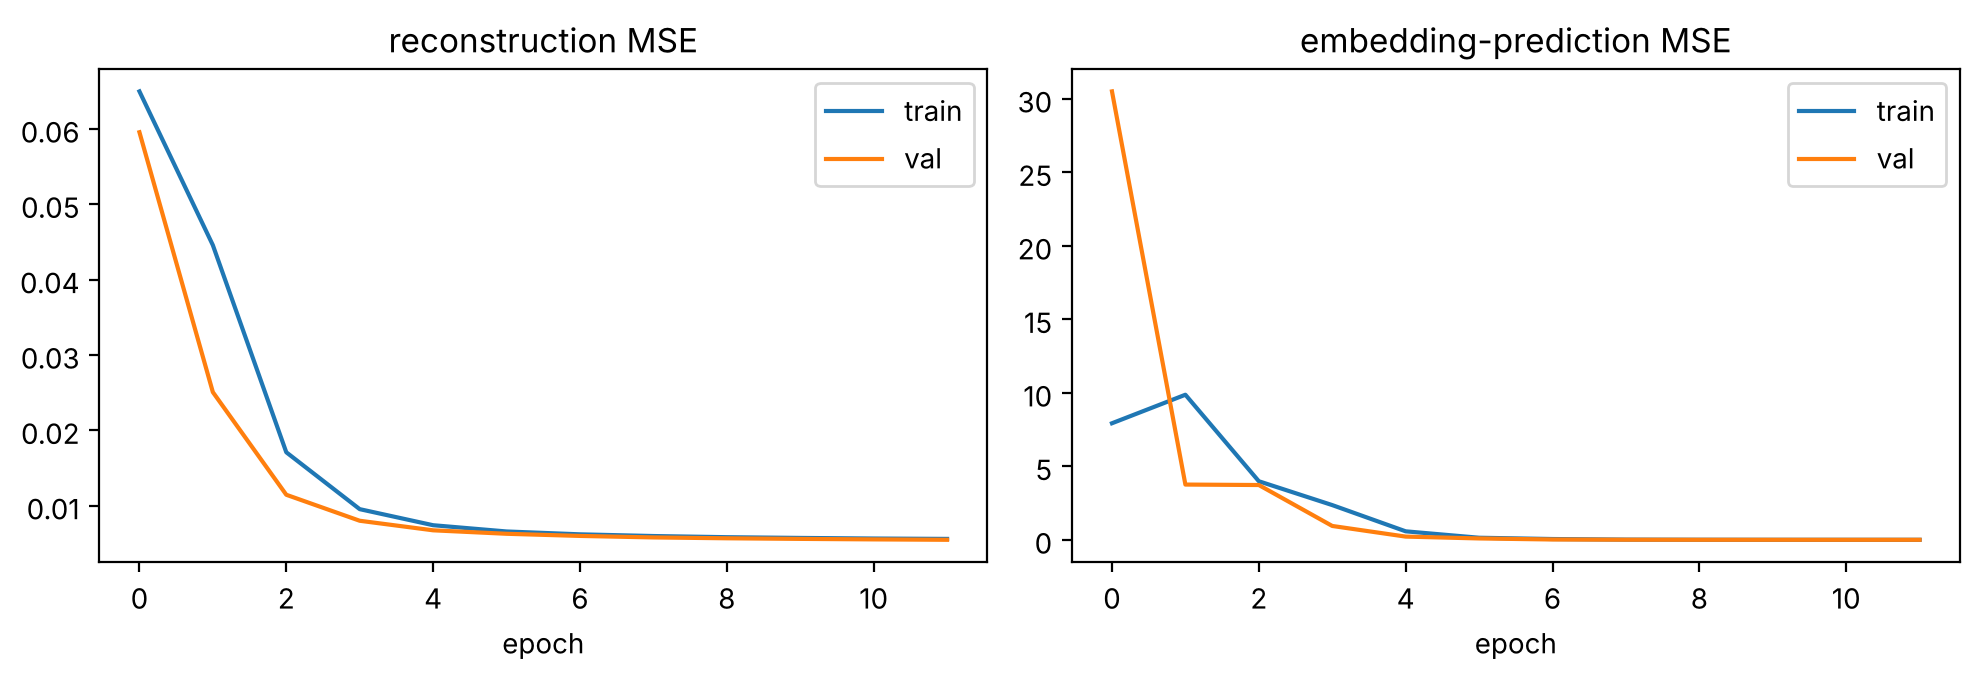

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(history["train_recon"], label="train"); axes[0].plot(history["val_recon"], label="val")
axes[0].set_title("reconstruction MSE"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(history["train_embed"], label="train"); axes[1].plot(history["val_embed"], label="val")
axes[1].set_title("embedding-prediction MSE"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout(); plt.show()


In [3]:
import os
os.makedirs("checkpoints", exist_ok=True)
torch.save(model.state_dict(), "checkpoints/world_model.pt")
print("saved to checkpoints/world_model.pt")


saved to checkpoints/world_model.pt


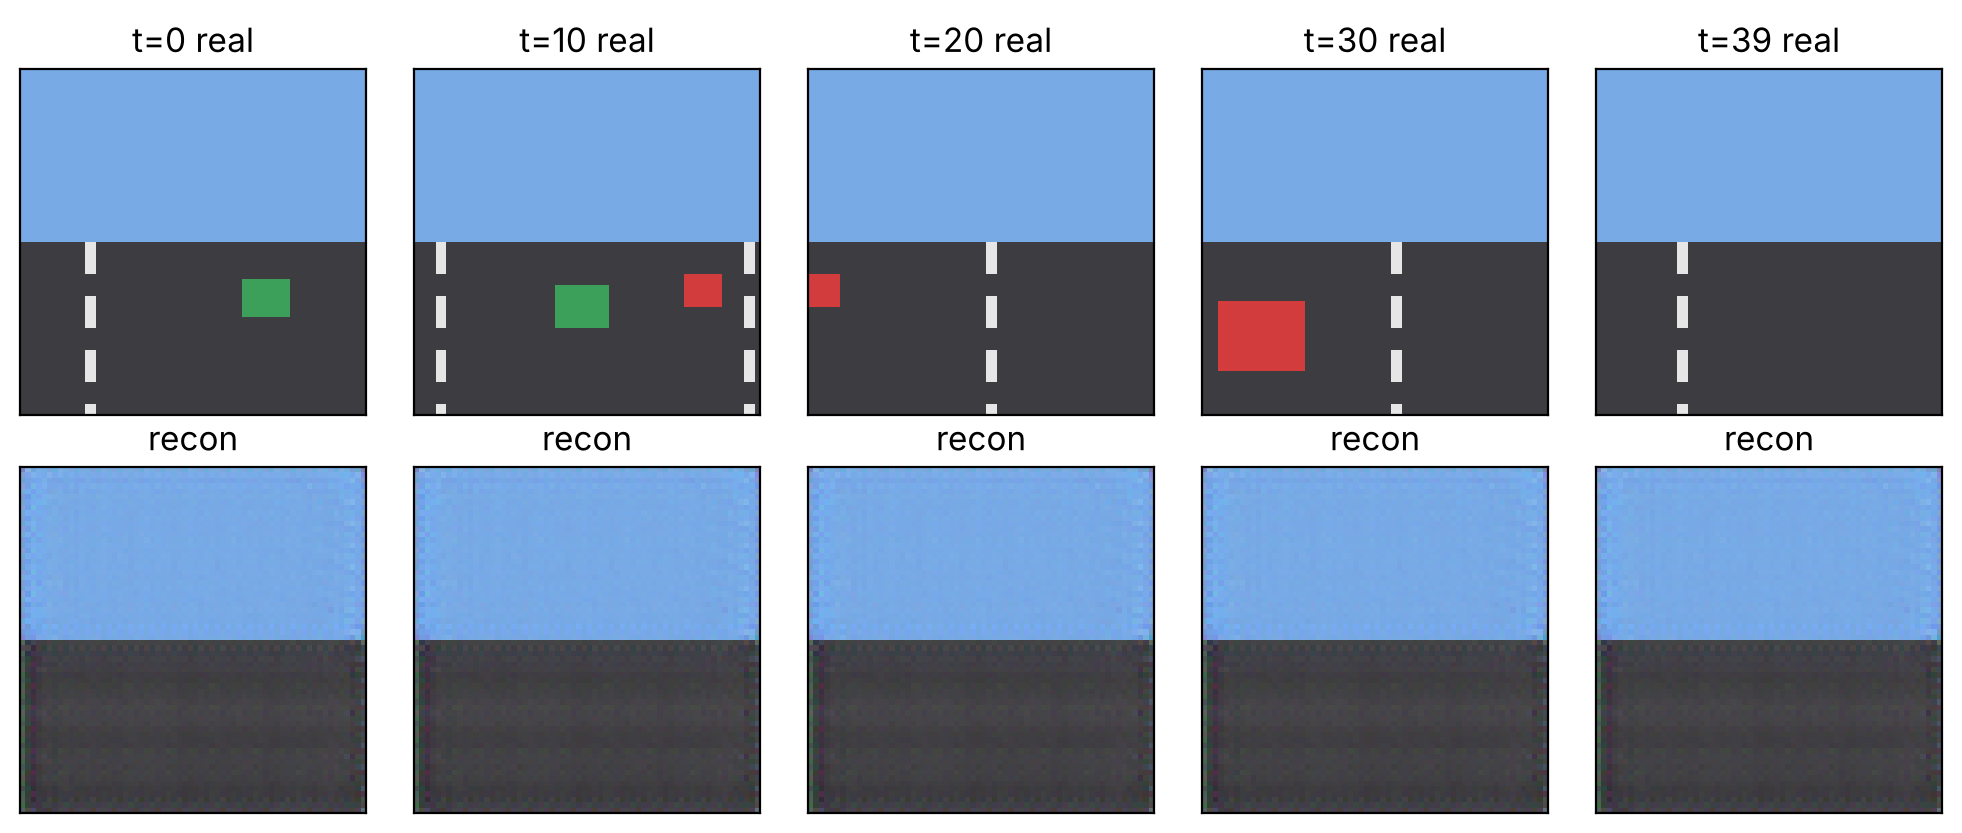

In [4]:
# 학습 후 재구성 품질 눈으로 확인 (posterior, teacher-forced)
model.eval()
frames, actions, states = val_ds[0]
frames, actions = frames.unsqueeze(0).to(device), actions.unsqueeze(0).to(device)
h = model.init_hidden(1, device)
recons = []
with torch.no_grad():
    for t in range(frames.shape[1]):
        h, recon, _ = model.posterior_step(h, frames[:, t], actions[:, t])
        recons.append(recon[0].cpu().numpy())

timesteps = [0, 10, 20, 30, 39]
fig, axes = plt.subplots(2, len(timesteps), figsize=(len(timesteps) * 2.0, 4.2))
for col, t in enumerate(timesteps):
    axes[0, col].imshow(W.frame_to_uint8(frames[0, t, 0].cpu().numpy())); axes[0, col].set_title(f"t={t} real")
    axes[1, col].imshow(W.frame_to_uint8(recons[t][0])); axes[1, col].set_title("recon")
    for r in range(2):
        axes[r, col].set_xticks([]); axes[r, col].set_yticks([])
plt.tight_layout(); plt.show()


재구성(두 번째 줄)이 실제 프레임(첫 번째 줄)의 도로/차선/앞차 위치를 어느 정도 따라가면
학습이 잘 된 것입니다. 다음 노트북(`04`)에서는 이 모델에게 **관측을 끊고 혼자 상상하게
시켜서**, 어디서부터 현실과 어긋나기 시작하는지를 직접 찾아봅니다.
